In [132]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [158]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import glob
from udag_tools import *

### Files

In [141]:
import os
import glob

#var='RRm'
# 'TG'
season='_sem_' 
#scenarios = ['rcp26','rcp45', 'rcp85']
scenarios=['ssp370',]

#create_df(scenarios, var, season)
create_df(scenarios,var='RRm', season='_sem_', what='ssp')
          #what='ssp')


Saved 560 rows to /home/g/g300047/SCRIPTS/github/udag/df_RRm_sem_ssp.csv


In [143]:
import glob
#calculate differences
wkd=os.getcwd()
#var='TG'
var='RRm'

# Achtung hier könne diff auch mit eingebunden werden, wenn es schon existiert
# vorher löschen am besten alle df*.csv ganz zu anfang löschen

files = sorted(glob.glob(os.path.join(wkd, "df_"+var+"*.csv")))
df = pd.concat([pd.read_csv(file) for file in files], ignore_index=True)

cal_diff(df,wkd,var)

RRm_2040_2069
RRm_2070_2099
Saved 1323 rows to /home/g/g300047/SCRIPTS/github/udag/df_RRm_diff.csv


data frames sind nun da für die plots:
df_TG_diff.csv
und 
df_RRm_diff.csv

Index(['realization', 'region', 'TG_1971_2000', 'ci_name', 'ci_frequency',
       'standard_name', 'units', 'season', 'scenario', 'TG_2040_2069',
       'TG_2070_2099', 'TG_2040_2069_diff', 'TG_2070_2099_diff'],
      dtype='object')
plot for :  Duisburg_3x3


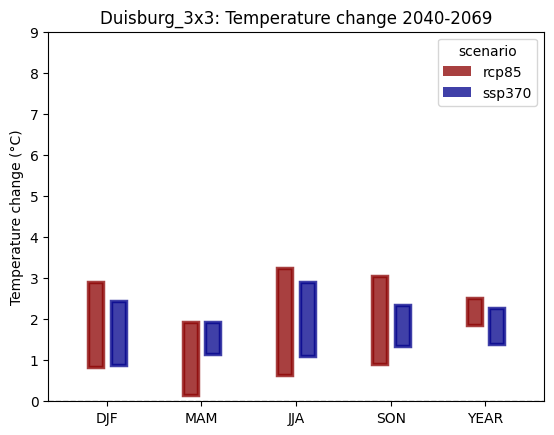

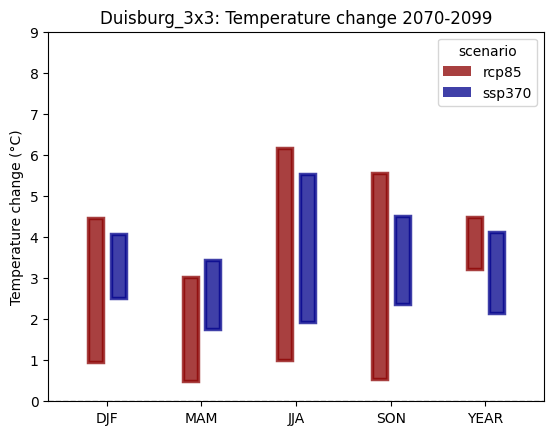

plot for :  Germany


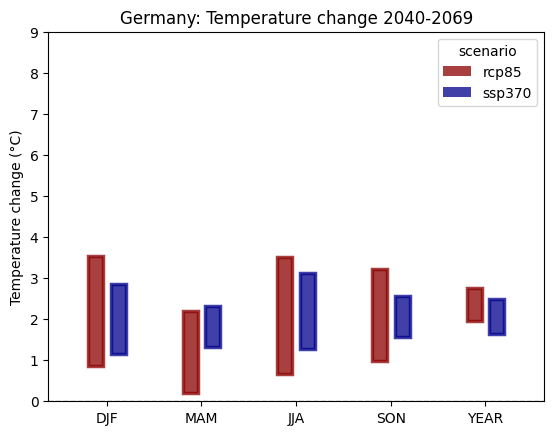

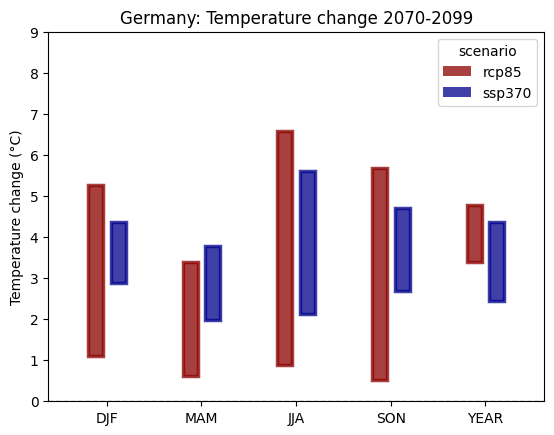

plot for :  IAWAK-EE


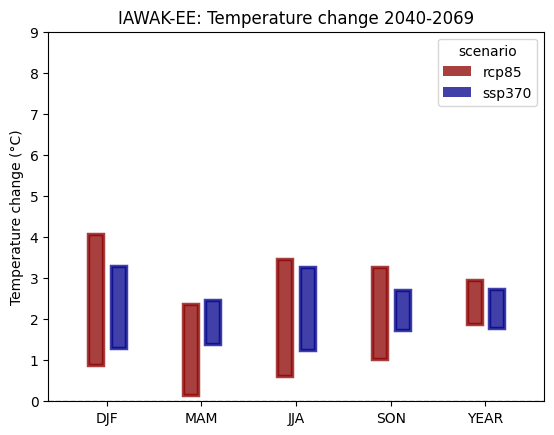

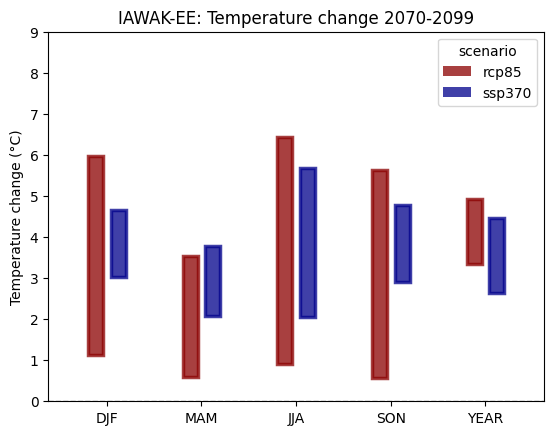

plot for :  ISAP


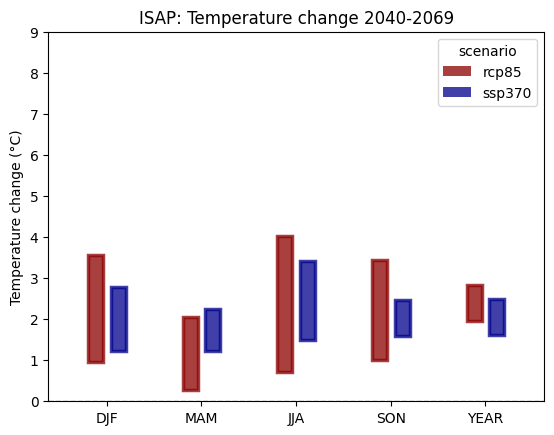

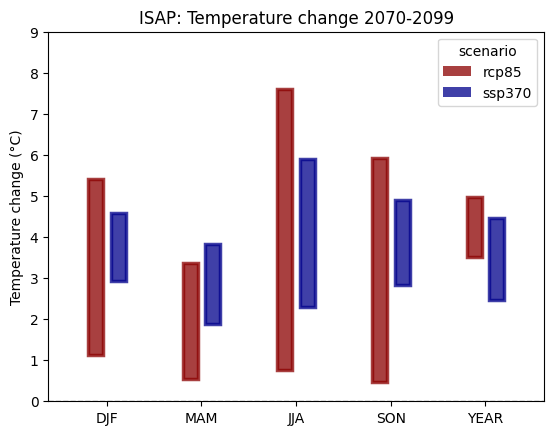

plot for :  KARE


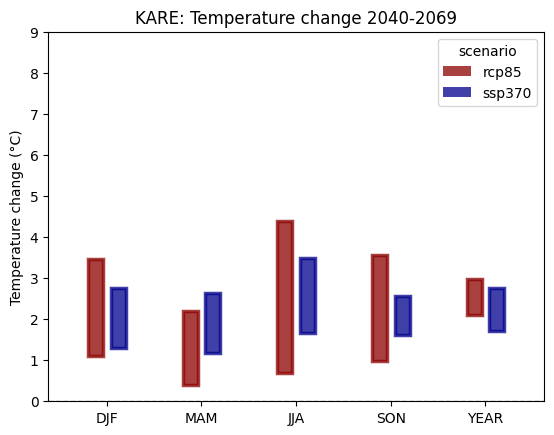

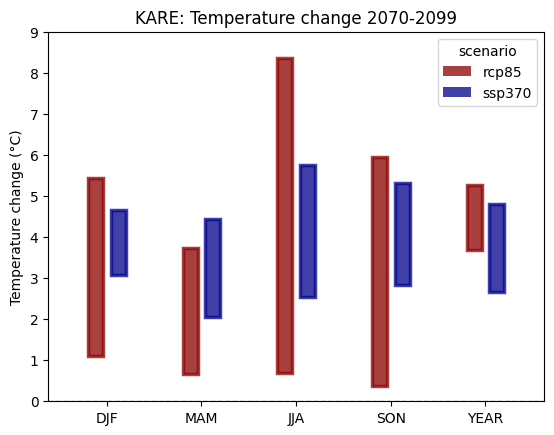

plot for :  WAKOS_Festland


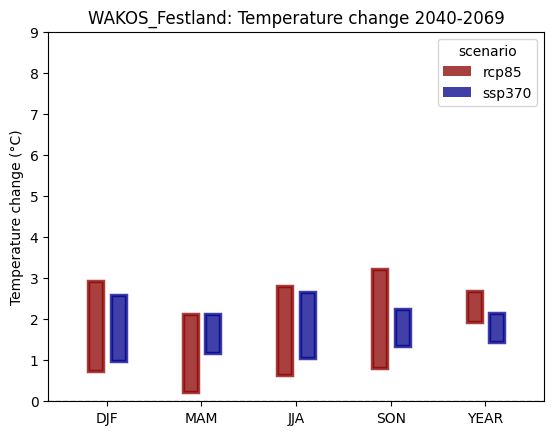

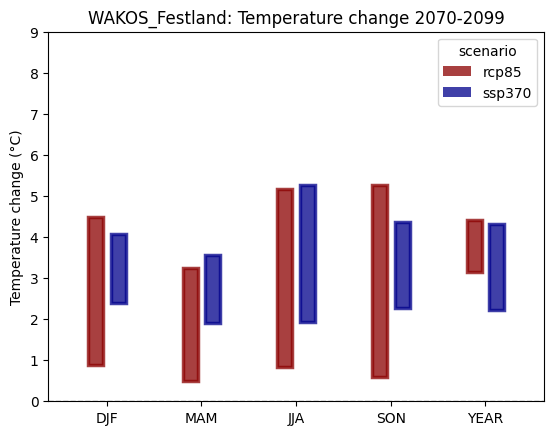

plot for :  klimakonform


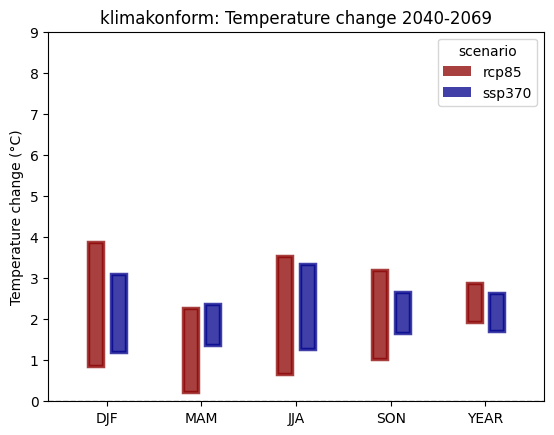

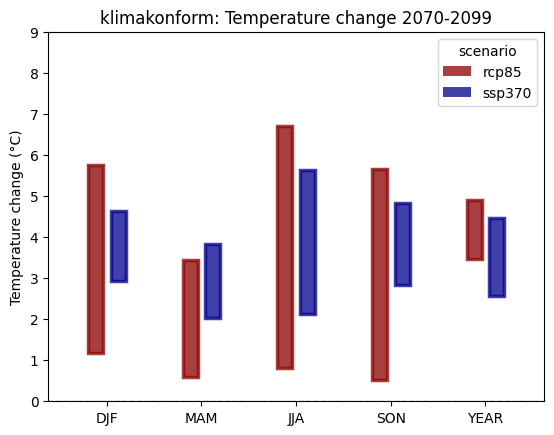

In [160]:
plotdir='/home/g/g300047/SCRIPTS/github/udag/plots'

#df=pd.read_csv('/home/g/g300047/SCRIPTS/github/udag/df_RRm_diff.csv')
df=pd.read_csv('/home/g/g300047/SCRIPTS/github/udag/df_TG_diff.csv')
print(df.columns)
time_slice= ['TG_2040_2069_diff','TG_2070_2099_diff']
#time_slice= ['RRm_2040_2069_diff_pro','RRm_2070_2099_diff_pro']
ylabel="Temperature change (°C)"
#ylabel="Precipitation change[%]"
# y-limit
y1=0
y2=9
#y1=-80
#y2=60

for r in df['region'].unique():
    print ('plot for : ', r)
    dfr= df.loc[df["region"] == r].copy()
    
    for col in time_slice:
        ts = f"{col.split('_')[1]}-{col.split('_')[2]}"

        plot_change(plotdir,dfr,col,ylabel,r,y1,y2,title=f"{r}: Temperature change {ts}")

In [151]:
df.loc[df["region"] == "WAKOS_Festland", "RRm_2070_2099_diff_pro"].min()

-59.006933580052376